# Lab 7: Go-to-goal
# Adhambek Yashnarbekov — 240062

The program is `Fixed_1x1_trajectory.qrs` from the lecture with my waypoints for "62" (in metres in TRIK, in cm here). The robot starts in the left end of the middle line of the 6, facing +x. The 6 is drawn as middle line, lower right side, bottom, left side, top. Then it crosses the gap to (35, 25) and draws the 2: top to (60, 25), right side down to (60, 0), middle back to (35, 0), left side down to (35, -25), bottom to (60, -25).

Gains (the same in both programs): K_θ = 80 (`u = 80 * err`), K_v = 500 and v_max = 50 (`mov = min(500 * dist, 50) * cos(err)`), acceptance radius ε = 0.03 m. Only r and B are different: r = 0.028 m, B = 0.154 m in the simulator and r = 0.0375 m, B = 0.194 m on the real robot.

Upload `odometry_data_sim.txt` and `odometry_data_real.txt` in the next cell.

In [1]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

uploaded = files.upload()           # select BOTH txt files

Saving odometry_data_real.txt to odometry_data_real.txt
Saving odometry_data_sim.txt to odometry_data_sim.txt


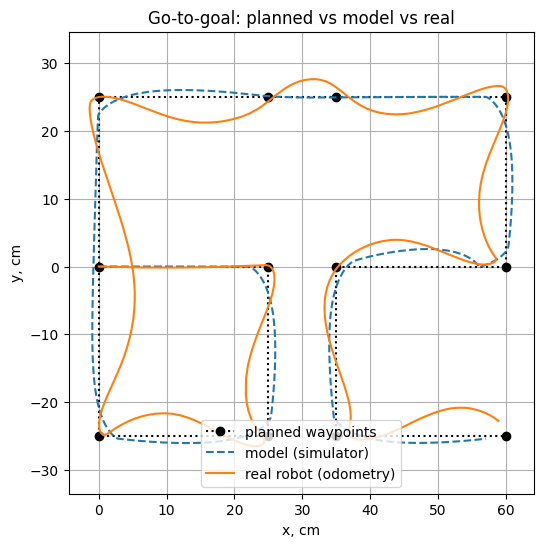

In [2]:
# Planned waypoints: copy them from your TRIK program
wp = np.array([[0, 0], [25, 0], [25, -25], [0, -25], [0, 25], [25, 25], [35, 25], [60, 25], [60, 0], [35, 0], [35, -25], [60, -25]])

x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt',  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)

# 1. Planned path vs simulated vs real
plt.figure(figsize=(6, 6))
plt.plot(wp[:, 0], wp[:, 1], 'k:o', label='planned waypoints')
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, cm'); plt.ylabel('y, cm')
plt.title('Go-to-goal: planned vs model vs real')
plt.show()

In both runs the robot drew the 62. The simulator keeps about 2 cm from every corner (this is ε) and its lines are straight. The real robot cuts the corners by the same 2–3 cm, but its straight pieces are wavy: after every turn it swings about 30° past the direction to the next point and comes back, so it is up to 5 cm off the line. It also drives faster, so the real run took 15.2 s against 27.5 s.

In [3]:
# 2. How close did each run get to each waypoint?
def waypoint_miss(x, y, wp):
    return np.array([np.min(np.hypot(x - px, y - py)) for px, py in wp])

miss_s = waypoint_miss(x_s, y_s, wp)
miss_r = waypoint_miss(x_r, y_r, wp)
for i, (ms, mr) in enumerate(zip(miss_s, miss_r)):
    print(f'Waypoint {i} {tuple(wp[i])}: sim {ms:5.1f} cm | real {mr:5.1f} cm')

Waypoint 0 (np.int64(0), np.int64(0)): sim   0.0 cm | real   0.0 cm
Waypoint 1 (np.int64(25), np.int64(0)): sim   1.8 cm | real   0.2 cm
Waypoint 2 (np.int64(25), np.int64(-25)): sim   1.6 cm | real   0.8 cm
Waypoint 3 (np.int64(0), np.int64(-25)): sim   1.7 cm | real   0.6 cm
Waypoint 4 (np.int64(0), np.int64(25)): sim   1.8 cm | real   0.1 cm
Waypoint 5 (np.int64(25), np.int64(25)): sim   0.1 cm | real   0.5 cm
Waypoint 6 (np.int64(35), np.int64(25)): sim   0.1 cm | real   1.1 cm
Waypoint 7 (np.int64(60), np.int64(25)): sim   1.9 cm | real   0.4 cm
Waypoint 8 (np.int64(60), np.int64(0)): sim   1.6 cm | real   1.7 cm
Waypoint 9 (np.int64(35), np.int64(0)): sim   1.3 cm | real   0.4 cm
Waypoint 10 (np.int64(35), np.int64(-25)): sim   1.6 cm | real   1.8 cm
Waypoint 11 (np.int64(60), np.int64(-25)): sim   2.9 cm | real   2.5 cm


In [4]:
# 3. Run time
print(f'Run time: sim {(t_s[-1]-t_s[0])/1000:.1f} s | real {(t_r[-1]-t_r[0])/1000:.1f} s')

Run time: sim 27.5 s | real 15.2 s


## Measured end point

Before the run I put coin 1 next to the left wheel and coin 2 next to the right wheel, where they touch the floor. After the run I did the same with coins 3 and 4 and measured the distances between the coins with a tape: 1–2 = 21 cm, 1–3 = 62 cm, 1–4 = 57 cm, 2–3 = 62 cm, 2–4 = 46 cm. With x along the start direction and y to the left, coin 1 is at (0, 10.5) and coin 2 at (0, -10.5). From the two distances to coins 1 and 2 each end coin is found as the crossing of two circles: coin 3 is at (61, 0) and coin 4 at (43, -27). The robot centre is the middle between them. By these numbers coins 3 and 4 come out 32 cm apart instead of 21, so one distance was measured a few cm off and the tape point is only good to a few cm.

In [5]:
d12, d13, d14, d23, d24 = 21, 62, 57, 62, 46     # tape, cm

def coin(a, b):                      # a = distance from coin 1, b = distance from coin 2
    y = (b**2 - a**2) / (2 * d12)
    x = np.sqrt(a**2 - (y - d12 / 2)**2)
    return x, y

x3, y3 = coin(d13, d23)
x4, y4 = coin(d14, d24)
x_tape, y_tape = (x3 + x4) / 2, (y3 + y4) / 2

print(f'Coin 3: ({x3:.1f}, {y3:.1f}) cm, coin 4: ({x4:.1f}, {y4:.1f}) cm')
print(f'Last waypoint:        x = {wp[-1, 0]:.1f} cm, y = {wp[-1, 1]:.1f} cm')
print(f'Odometry (last line): x = {x_r[-1]:.1f} cm, y = {y_r[-1]:.1f} cm')
print(f'Tape:                 x = {x_tape:.1f} cm, y = {y_tape:.1f} cm')
print(f'Tape - odometry: {np.hypot(x_r[-1] - x_tape, y_r[-1] - y_tape):.1f} cm, '
      f'tape - last waypoint: {np.hypot(wp[-1, 0] - x_tape, wp[-1, 1] - y_tape):.1f} cm')

Coin 3: (61.1, 0.0) cm, coin 4: (42.9, -27.0) cm
Last waypoint:        x = 60.0 cm, y = -25.0 cm
Odometry (last line): x = 58.9 cm, y = -22.8 cm
Tape:                 x = 52.0 cm, y = -13.5 cm
Tape - odometry: 11.6 cm, tape - last waypoint: 14.0 cm


## Conclusions

Every corner is cut by 2–3 cm in both runs, and this comes from the acceptance radius ε = 0.03 m: the waypoint counts as reached 3 cm before it and the robot turns to the next one at once, so it never touches the corner itself. No waypoint is overshot (real miss 0.1–2.5 cm, simulator 0.1–2.9 cm), but on the real robot the heading overshoots after every turn by about 30° and the straight pieces come out wavy, up to 5 cm off the line; this is K_θ = 80, which is still a bit too high for the real motors that answer with a delay (Lab 5), while the simulated motors react at once and the lines stay straight. The real run is almost twice as fast (15.2 s against 27.5 s) because the real wheels are bigger and the same power gives a higher speed. The remaining gap is a localization problem, not a control problem: the controller thinks it finished at (59, -23), 2.5 cm from the last waypoint, but the tape shows the robot at about (52, -14), 12 cm away from where the odometry says and 14 cm from the last waypoint. The controller did its job on the position it was given; the position itself was wrong, most likely because of wheel slip in the fast turns, which the encoders cannot see, like in Lab 6.